In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, precision_score, recall_score

In [3]:
df = pd.read_excel("/content/diabetesxl.xlsx")
df.head(10)

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive
5,5,116,74,0,0,25.6,0.201,30,tested_negative
6,3,78,50,32,88,31.0,0.248,26,tested_positive
7,10,115,0,0,0,35.3,0.134,29,tested_negative
8,2,197,70,45,543,30.5,0.158,53,tested_positive
9,8,125,96,0,0,0.0,0.232,54,tested_positive


In [4]:
x = df[["age","mass","insu","plas"]]
y = df["class"]
print("Feature shape:", x.shape, "Target shape:", y.shape)

Feature shape: (768, 4) Target shape: (768,)


In [5]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=42)
print("records for training:",len(x_train))
print("records for testing:",len(x_test))

records for training: 614
records for testing: 154


In [6]:
RF = RandomForestClassifier()
RF.fit(x_train, y_train)

RandomForestClassifier()

In [7]:
y_pred = RF.predict(x_test)

comparison = pd.DataFrame({
    'actual_results': y_test,
    'results_by_model': y_pred
})

comparison.head(10)

,actual_results,results_by_model
668,tested_negative,tested_positive
324,tested_negative,tested_negative
624,tested_negative,tested_negative
690,tested_negative,tested_negative
473,tested_negative,tested_positive
204,tested_negative,tested_positive
97,tested_negative,tested_negative
336,tested_negative,tested_positive
568,tested_negative,tested_negative
148,tested_negative,tested_positive


In [9]:
age = int(input("Enter age: "))
mass = int(input("Enter the mass: "))
insulin = int(input("Enter the insulin: "))
plasma = int(input("Enter the plasma: "))

pred = RF1.predict([[age, mass, insulin, plasma]])

if pred[0] == "tested_negative1":
    print("Congratulations! You are safe.")
else:
    print("Please consult a doctor!!!.")

Enter age: 20
Enter the mass: 45
Enter the insulin: 160
Enter the plasma: 180
Please consult a doctor!!!.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [10]:
print("accuracy:",accuracy_score(y_test,y_pred))
print("precison:",precision_score(y_test,y_pred,pos_label="tested_positive"))
print("recall:",recall_score(y_test,y_pred,pos_label="tested_positive"))
print("f1 score:",f1_score(y_test,y_pred,pos_label="tested_positive"))
print("confusion matrix:\n",confusion_matrix(y_test,y_pred))

accuracy: 0.7207792207792207
precison: 0.5967741935483871
recall: 0.6727272727272727
f1 score: 0.6324786324786325
confusion matrix:
 [[74 25]
 [18 37]]


<function matplotlib.pyplot.show(close=None, block=None)>

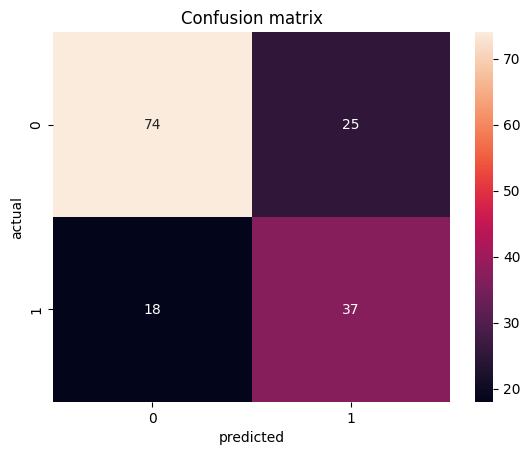

In [11]:
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm , annot=True)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix")
plt.show

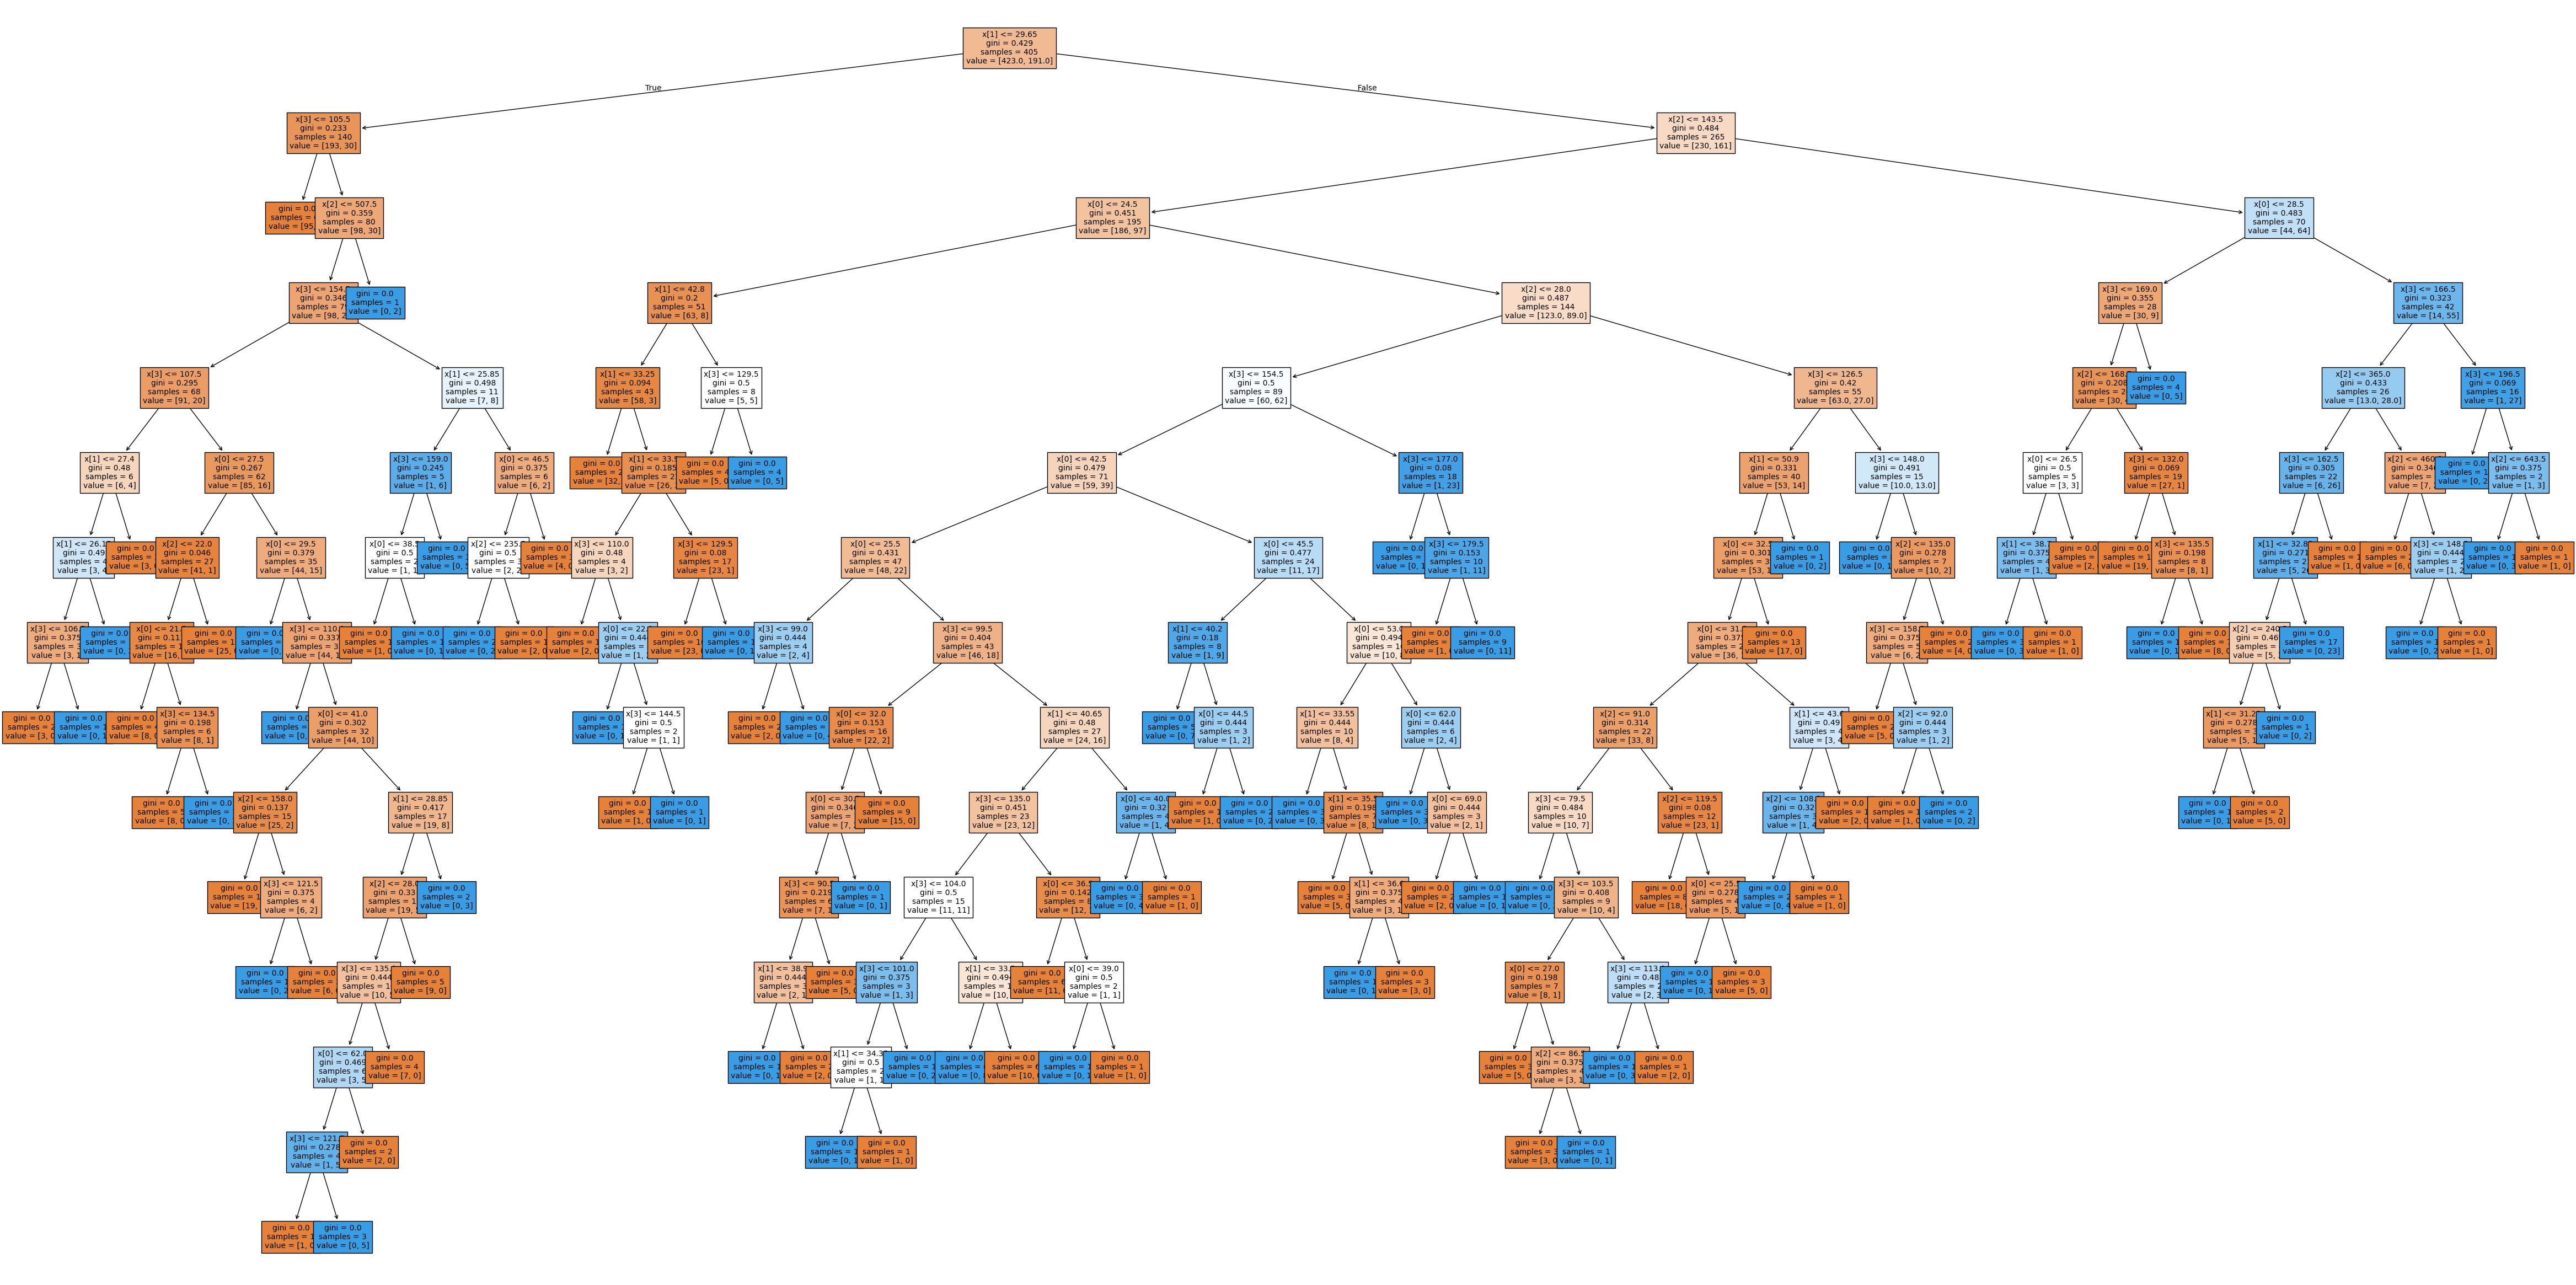

In [13]:
from sklearn.tree import plot_tree

plt.figure(figsize=(60, 30))

plot_tree(
    RF.estimators_[0],
    fontsize=10,
    filled=True
)

plt.savefig("RandomForest_Tree.pdf", bbox_inches="tight")
plt.show()